<table style="border:none"><tr>
<td style="border:none; vertical-align:middle">
<h1 style="color:#54A021; margin-bottom:0">Atividade 7: Lab QPSK — Simulação de modulação e demodulação</h1>
<p style="color:#2C3C43; margin-top:4px"><b>SCM203405 — Sistemas de Comunicação</b><br>
Superior em Eletrônica Industrial – IFSC Florianópolis</p>

</td>
</tr></table>

**Mateus Salgado Barboza Costa** · Matrícula **202110810789** · 04/11/2026

### Objetivos

Ao final deste laboratório você deverá ser capaz de implementar, bloco a bloco, um modulador e um demodulador QPSK em Python; relacionar cada bloco do diagrama com uma linha de código; interpretar o sinal $s(t)$ no tempo e na frequência; e explicar, com suas palavras, por que o correlator recupera exatamente os símbolos transmitidos (e quando ele deixa de recuperar).

### Como este laboratório funciona

Cada aluno trabalha com **parâmetros próprios**, gerados a partir da matrícula (sequência de 10 bits, $E_b$, taxa de bits e frequência da portadora).

Antes de escrever qualquer código, você fará uma **previsão à mão** (Parte 0) do que a simulação deve mostrar.

O uso de IA (ChatGPT, Claude, Copilot etc.) é **permitido como apoio**, assim como consultar um livro ou um colega. Em troca, você registra no **log de uso de IA** ao final do notebook o que perguntou e como verificou a resposta — como uma citação de fonte.


---
## Configuração e parâmetros individualizados

Execute a célula abaixo **depois de colocar a sua matrícula**. Não altere a função `gerar_parametros` — o professor usa a mesma função para conferir o seu resultado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Paleta institucional (IFSC)
VERDE, VERDE_CLARO, CINZA = "#54A021", "#90C226", "#2C3C43"
LARANJA, VERMELHO, AMARELO = "#E76618", "#C42F1A", "#E6B91E"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.family": "DejaVu Sans", "axes.titleweight": "bold"})

MATRICULA = "202110810789"   # <<< SUBSTITUA PELA SUA MATRÍCULA

def gerar_parametros(matricula):
    digitos = "".join(c for c in str(matricula) if c.isdigit())
    semente = int(digitos) % (2**32)
    rng = np.random.default_rng(semente)
    bits = rng.integers(0, 2, 10)
    Eb = [0.5, 1.0, 2.0, 4.0][semente % 4]              # energia por bit [J]
    Rb = [1e3, 2e3, 4e3][(semente // 4) % 3]            # taxa de bits [bit/s]
    k  = [2, 3, 4, 5][(semente // 12) % 4]              # ciclos de portadora por símbolo
    return bits, Eb, Rb, k

bits, Eb, Rb, k = gerar_parametros(MATRICULA)

Tb = 1 / Rb            # duração de bit
T  = 2 * Tb            # duração de símbolo QPSK (dibit)
fc = k / T             # portadora: número inteiro de ciclos por símbolo
Nb = 100               # amostras por bit
Ns = 2 * Nb            # amostras por símbolo
fs = Nb / Tb           # frequência de amostragem
dt = 1 / fs

print(f"Matrícula ........: {MATRICULA}")
print(f"Bits (b0 ... b9) .: {bits}")
print(f"Eb ...............: {Eb} J    ->  amplitude NRZ = ±√Eb = ±{np.sqrt(Eb):.4f}")
print(f"Rb ...............: {Rb/1e3:.0f} kbit/s   (Tb = {Tb*1e3:.3f} ms,  T = 2Tb = {T*1e3:.3f} ms)")
print(f"fc ...............: {fc/1e3:.2f} kHz  ({k} ciclos por símbolo)")
print(f"fs ...............: {fs/1e3:.0f} kHz  ({Nb} amostras/bit)")

Matrícula ........: 202110810789
Bits (b0 ... b9) .: [0 0 0 0 0 0 1 1 0 1]
Eb ...............: 1.0 J    ->  amplitude NRZ = ±√Eb = ±1.0000
Rb ...............: 1 kbit/s   (Tb = 1.000 ms,  T = 2Tb = 2.000 ms)
fc ...............: 2.50 kHz  (5 ciclos por símbolo)
fs ...............: 100 kHz  (100 amostras/bit)


In [2]:
# Funções auxiliares de gráfico (já prontas — não é preciso alterar)

def _faltando(*vs):
    if any(v is None for v in vs):
        print("⚠  Complete os TODOs das células anteriores antes de executar esta.")
        return True
    return False

def marcar_simbolos(ax, nsim, T):
    for i in range(nsim + 1):
        ax.axvline(i * T * 1e3, color=CINZA, lw=0.6, ls=":")

def plot_tempo(t, bits, a1t, a2t, s, T, Tb):
    if _faltando(a1t, a2t, s): return
    nsim = len(bits) // 2
    tb = np.arange(len(bits) + 1) * Tb * 1e3
    fig, ax = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
    ax[0].stairs(bits, tb, color=CINZA, lw=2)
    for i, b in enumerate(bits):
        ax[0].text((i + 0.5) * Tb * 1e3, 1.15, f"b{i}={b}", ha="center", fontsize=8)
    ax[0].set_ylim(-0.2, 1.4); ax[0].set_title("Bits de informação (serial)")
    ax[1].plot(t * 1e3, a1t, color=VERDE, lw=2);   ax[1].set_title("a₁(t) — canal I (bits pares b0, b2, ...)")
    ax[2].plot(t * 1e3, a2t, color=LARANJA, lw=2); ax[2].set_title("a₂(t) — canal Q (bits ímpares b1, b3, ...)")
    ax[3].plot(t * 1e3, s, color=CINZA, lw=1);     ax[3].set_title("Sinal QPSK s(t)")
    ax[3].set_xlabel("t [ms]")
    for a in ax: marcar_simbolos(a, nsim, T)
    plt.tight_layout(); plt.show()

def plot_espectro(s, fs, fc, T, nfft=2**16):
    if _faltando(s): return
    S = np.fft.rfft(s, nfft)
    f = np.fft.rfftfreq(nfft, 1 / fs)
    mag = np.abs(S) / np.max(np.abs(S))
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for a, y, lab in [(ax[0], mag, "|S(f)| normalizado"),
                      (ax[1], 20 * np.log10(mag + 1e-12), "|S(f)| [dB]")]:
        a.plot(f / 1e3, y, color=VERDE, lw=1.2)
        a.axvline(fc / 1e3, color=VERMELHO, ls="--", lw=1, label="fc")
        for m in (-1, 1):
            a.axvline((fc + m / T) / 1e3, color=LARANJA, ls=":", lw=1.2,
                      label="fc ± 1/T" if m == 1 else None)
        a.set_xlim(0, (fc + 5 / T) / 1e3); a.set_xlabel("f [kHz]"); a.set_ylabel(lab)
    ax[1].set_ylim(-60, 3); ax[0].legend()
    fig.suptitle("Espectro de s(t) (FFT com zero-padding)", fontweight="bold")
    plt.tight_layout(); plt.show()

def plot_constelacao(a1k, a2k, x1=None, x2=None, Eb=1.0, titulo="Constelação QPSK"):
    if _faltando(a1k, a2k): return
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    if x1 is not None:
        ax.scatter(x1, x2, s=12, color=VERDE_CLARO, alpha=0.5, label="saída do correlator (x₁, x₂)")
    ax.scatter(a1k, a2k, s=90, marker="x", color=VERMELHO, lw=2, label="símbolos transmitidos (a₁, a₂)")
    L = 2.2 * np.sqrt(Eb)
    ax.axhline(0, color=CINZA, lw=0.8); ax.axvline(0, color=CINZA, lw=0.8)
    ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_aspect("equal")
    ax.set_xlabel("φ₁ (em fase)"); ax.set_ylabel("φ₂ (quadratura)")
    ax.set_title(titulo); ax.legend(fontsize=7, loc="lower left")
    plt.tight_layout(); plt.show()

def plot_correlador(t, s, phi1, phi2, Ns, dt, T):
    if _faltando(s, phi1, phi2): return
    nsim = len(s) // Ns
    y1 = np.cumsum((s * phi1).reshape(nsim, Ns), axis=1).ravel() * dt
    y2 = np.cumsum((s * phi2).reshape(nsim, Ns), axis=1).ravel() * dt
    fig, ax = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True)
    for a, y, c, nome in [(ax[0], y1, VERDE, "x₁"), (ax[1], y2, LARANJA, "x₂")]:
        a.plot(t * 1e3, y, color=c, lw=1.5)
        a.plot(t[Ns - 1::Ns] * 1e3, y[Ns - 1::Ns], "o", color=VERMELHO, label=f"{nome}[k] (amostra em t = kT)")
        marcar_simbolos(a, nsim, T); a.legend(fontsize=8, loc="upper right")
    ax[0].set_title("Integrador do canal I (reinicia a cada T)")
    ax[1].set_title("Integrador do canal Q (reinicia a cada T)"); ax[1].set_xlabel("t [ms]")
    plt.tight_layout(); plt.show()

def plot_bits(bits, bits_est):
    if _faltando(bits_est): return
    n = np.arange(len(bits))
    fig, ax = plt.subplots(2, 1, figsize=(9, 3.6), sharex=True)
    ax[0].stem(n, bits, linefmt=CINZA, markerfmt="o", basefmt=" "); ax[0].set_title("Bits transmitidos")
    ax[1].stem(n, bits_est, linefmt=VERDE, markerfmt="o", basefmt=" "); ax[1].set_title("Bits estimados (após P/S)")
    erros = np.flatnonzero(np.asarray(bits) != np.asarray(bits_est))
    for e in erros: ax[1].plot(e, bits_est[e], "o", ms=14, mfc="none", mec=VERMELHO, mew=2)
    ax[1].set_xticks(n); ax[1].set_xlabel("índice do bit")
    for a in ax: a.set_ylim(-0.3, 1.4)
    plt.tight_layout(); plt.show()



## Parte 0 — Previsão analítica para conferência
Cálculo digitado a partir dos parâmetros da matrícula. O roteiro solicita a foto ou o scan da previsão manuscrita em separado.

**0.1 · Tempo e energia.** Com 1.000 bit/s, cada bit dura 1 ms. Cada dibit ocupa 2 ms. Cinco ciclos nesse intervalo dão 2.500 Hz. Cada eixo vale ±1 e a energia do símbolo é 2 J.

**0.2 · Fase.** Os dibits 00, 00, 00, 11, 01 correspondem a (−1,−1), (−1,−1), (−1,−1), (+1,+1), (−1,+1). Os ângulos no plano I/Q são 225°, 225°, 225°, 45° e 135°. Em s(t) = A cos(2πfct − φ), o pico previsto é A = √(4Eb/T) = 44,72.

**0.3 · Correlação.** As bases completam cinco ciclos por símbolo. A integral do produto seno × cosseno é zero e a integral do quadrado de cada base normalizada vale um. Portanto, as amostras finais devem reproduzir cada par acima.

**0.4 · Espectro.** O pulso retangular de 2 ms tem o primeiro zero a 500 Hz do centro. Em banda passante, os primeiros nulos ao redor de 2.500 Hz ficam em 2.000 e 3.000 Hz, separados por 1.000 Hz.

---
## Parte 1 — Modulador QPSK

Implemente o modulador abaixo, bloco a bloco. Cada célula de código corresponde a um bloco do diagrama.

<p align="center">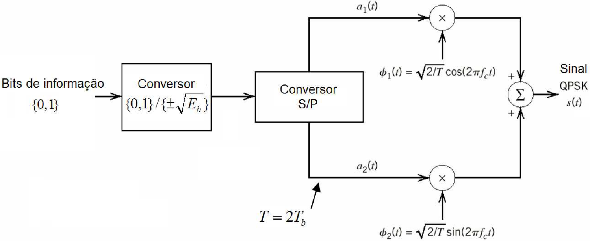</p>

O sinal transmitido, em sua forma geral para uma modulação em quadratura, é

$$s(t) = a_1(t)\,\phi_1(t) + a_2(t)\,\phi_2(t),$$

com funções-base ortonormais no intervalo de símbolo $T = 2T_b$:

$$\phi_1(t) = \sqrt{\tfrac{2}{T}}\cos(2\pi f_c t), \qquad \phi_2(t) = \sqrt{\tfrac{2}{T}}\sin(2\pi f_c t).$$

No caso particular do QPSK, $a_1, a_2 \in \{+\sqrt{E_b}, -\sqrt{E_b}\}$ e são constantes durante cada símbolo. Interpretação física: cada dibit escolhe um dos quatro pontos do plano $(\phi_1, \phi_2)$ — ou seja, uma das quatro **fases** de uma portadora de amplitude constante.

### 1.1 Conversor {0,1} → {±√Eb} (codificador NRZ polar)

O bloco Conversor é um codificador de linha NRZ polar: bit 1 → $+\sqrt{E_b}$, bit 0 → $-\sqrt{E_b}$.

In [3]:
def nrz_polar(bits, Eb):

    return np.where(np.asarray(bits) == 1, np.sqrt(Eb), -np.sqrt(Eb))

simbolos = nrz_polar(bits, Eb)
print("Símbolos NRZ:", simbolos)

Símbolos NRZ: [-1. -1. -1. -1. -1. -1.  1.  1. -1.  1.]


### 1.2 Conversor Serial/Paralelo (S/P)

O conversor S/P separa cada dibit: o **primeiro bit (par — even)** vai para o canal em fase, $a_1$, e o **segundo bit (ímpar — odd)** vai para o canal em quadratura, $a_2$. Cada saída tem agora a metade da taxa de bits, ou seja, um valor a cada $T = 2T_b$.

In [4]:
def serial_paralelo(simbolos):

    a1k = simbolos[::2]
    a2k = simbolos[1::2]
    return a1k, a2k

a1k, a2k = serial_paralelo(simbolos)
print("a1[k] (canal I):", a1k)
print("a2[k] (canal Q):", a2k)

a1[k] (canal I): [-1. -1. -1.  1. -1.]
a2[k] (canal Q): [-1. -1. -1.  1.  1.]


### 1.3 Formas de onda $a_1(t)$, $a_2(t)$ e funções-base

Cada valor de $a_1[k]$ e $a_2[k]$ deve ser mantido constante durante `Ns` amostras (um símbolo de duração $T$). Dica: pesquise `np.repeat`.

In [5]:
nsim = len(bits) // 2
t = np.arange(nsim * Ns) * dt          # eixo do tempo

a1t = np.repeat(a1k, Ns)
a2t = np.repeat(a2k, Ns)

phi1 = np.sqrt(2/T) * np.cos(2*np.pi*fc*t)
phi2 = np.sqrt(2/T) * np.sin(2*np.pi*fc*t)

### 1.4 Sinal QPSK $s(t)$ — somador

In [6]:

s = a1t*phi1 + a2t*phi2

if s is not None:
    print(f"Pico de s(t) simulado: {np.max(np.abs(s)):.4f}")

Pico de s(t) simulado: 44.7214


### 1.5 Resultados do modulador — tempo, frequência e constelação

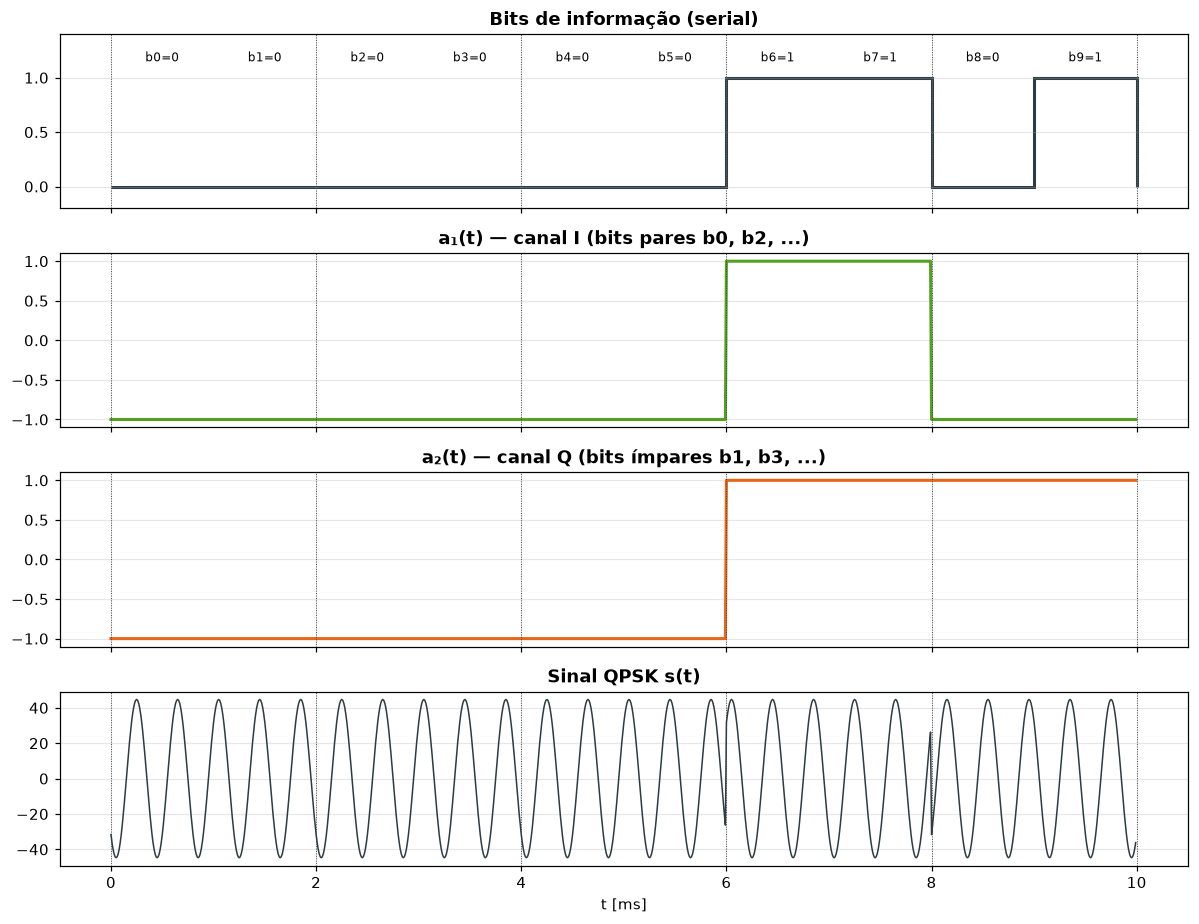

In [7]:
plot_tempo(t, bits, a1t, a2t, s, T, Tb)

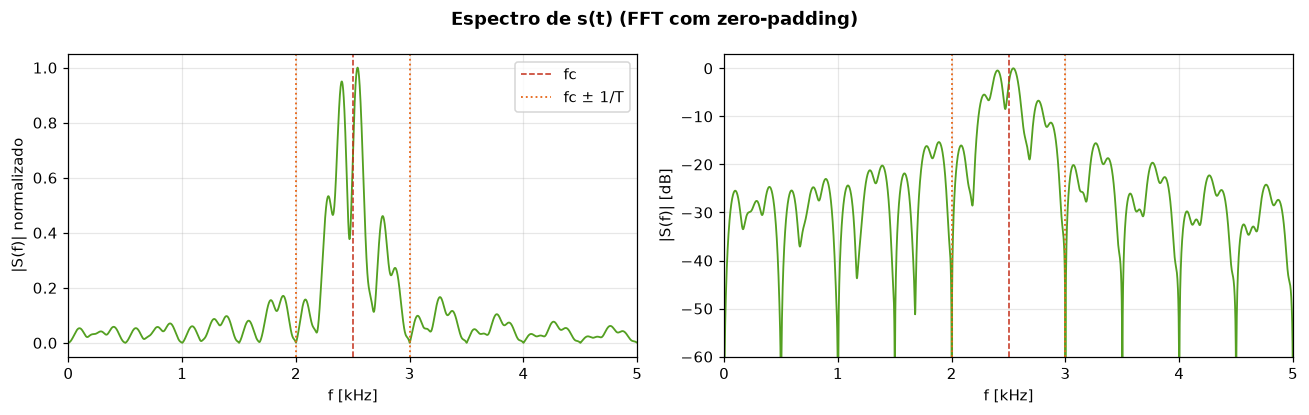

In [8]:
plot_espectro(s, fs, fc, T)

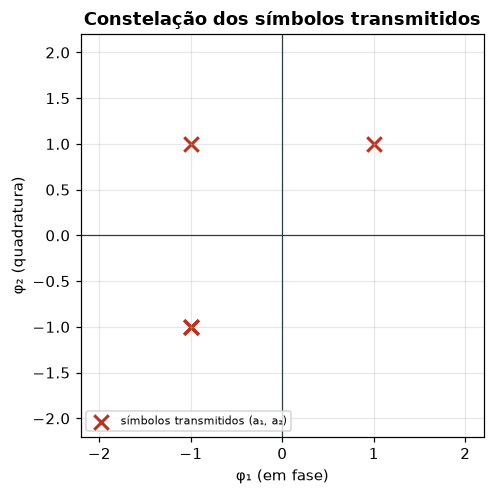

In [9]:
plot_constelacao(a1k, a2k, Eb=Eb, titulo="Constelação dos símbolos transmitidos")

**Questão 1** — Na figura de $s(t)$, identifique visualmente os instantes de mudança de fase. Escolha **uma** transição do seu sinal, diga de quanto foi o salto de fase (0°, ±90° ou 180°) e justifique a partir dos dibits envolvidos.

**Resposta.** No plano I/Q, os três primeiros dibits são 00, com fase de 225°. Por isso a senoide atravessa 2 e 4 ms sem mudar de fase. Aos 6 ms, 00 → 11 inverte os dois coeficientes e produz um salto de 180°. Aos 8 ms, 11 → 01 leva o ângulo do vetor de 45° a 135° (+90°). Na escrita do sinal como cosseno de 2πfct − φ, o deslocamento da portadora tem sinal oposto.

**Questão 2** — O espectro simulado confirma a sua previsão da Parte 0.4? Onde estão os nulos? Por que eles dependem de $1/T$ e não de $1/T_b$? Por que o espectro de apenas 5 símbolos não tem a forma "lisa" de $\text{sinc}^2$ vista na teoria?

**Resposta.** Sim. Os primeiros nulos previstos e observados ficam em 2 e 3 kHz, a 1/T = 500 Hz da portadora. Cada ramo mantém seu coeficiente por 2 ms, o tempo de um dibit. A FFT mostra a amplitude de uma realização curta, com três dibits idênticos em sequência. Já a envoltória sinc² descreve a densidade de potência média de uma sequência longa de símbolos aleatórios.

---
## Parte 2 — Demodulador QPSK (receptor por correlação)

<p align="center">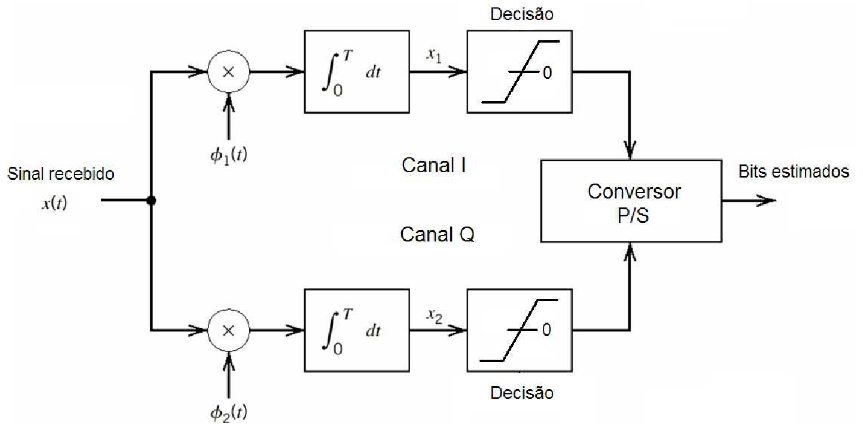</p>

Neste laboratório o canal é ideal: o sinal recebido é $x(t) = s(t)$. As funções-base $\phi_1(t)$ e $\phi_2(t)$ são as **mesmas** da transmissão. O correlator multiplica o sinal recebido pela função-base e integra em cada intervalo de símbolo:

$$x_1[k] = \int_{kT}^{(k+1)T} x(t)\,\phi_1(t)\,dt, \qquad x_2[k] = \int_{kT}^{(k+1)T} x(t)\,\phi_2(t)\,dt.$$

Em tempo discreto, a integral vira soma multiplicada por $dt$. Dica: reorganize o produto em uma matriz `(nsim, Ns)` com `reshape` e some ao longo de cada linha.

### 2.1 Correlatores (canais I e Q)

In [10]:
x = s   # canal ideal

def correlator(x, phi, Ns, dt):

    return (x * phi).reshape(-1, Ns).sum(axis=1) * dt

x1 = correlator(x, phi1, Ns, dt) if x is not None and phi1 is not None else None
x2 = correlator(x, phi2, Ns, dt) if x is not None and phi2 is not None else None
print("x1[k]:", None if x1 is None else np.round(x1, 4))
print("x2[k]:", None if x2 is None else np.round(x2, 4))

x1[k]: [-1. -1. -1.  1. -1.]
x2[k]: [-1. -1. -1.  1.  1.]


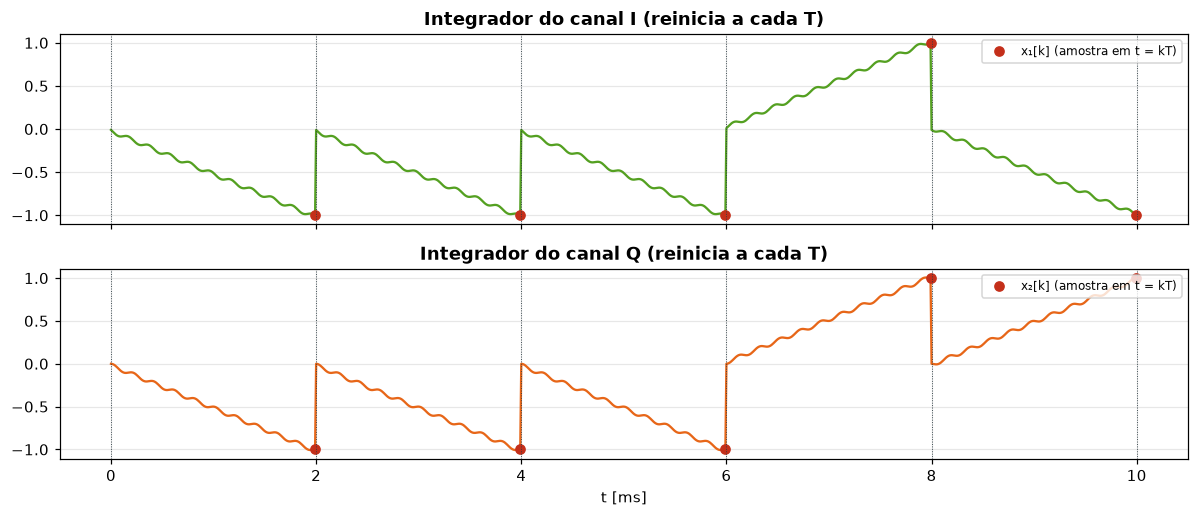

In [11]:
plot_correlador(t, x, phi1, phi2, Ns, dt, T)

### 2.2 Decisão e 2.3 Conversor Paralelo/Serial (P/S)

O bloco Decisão observa a **polaridade**: $x_i > 0 \Rightarrow$ bit 1; caso contrário, bit 0. O conversor P/S intercala novamente os bits: $\hat b_0$ (de $x_1[0]$), $\hat b_1$ (de $x_2[0]$), $\hat b_2$ (de $x_1[1]$), …

In [12]:
def decisao(xi):

    return (np.asarray(xi) > 0).astype(int)

def paralelo_serial(b_I, b_Q):

    return np.column_stack((b_I, b_Q)).ravel()

bits_est = None
if x1 is not None and x2 is not None:
    bits_est = paralelo_serial(decisao(x1), decisao(x2))

print("Bits transmitidos:", bits)
print("Bits estimados   :", bits_est)
if bits_est is not None:
    print("Erros de bit     :", int(np.sum(bits != bits_est)))

assert np.allclose(x1, a1k) and np.allclose(x2, a2k)
assert np.array_equal(bits, bits_est)

Bits transmitidos: [0 0 0 0 0 0 1 1 0 1]
Bits estimados   : [0 0 0 0 0 0 1 1 0 1]
Erros de bit     : 0


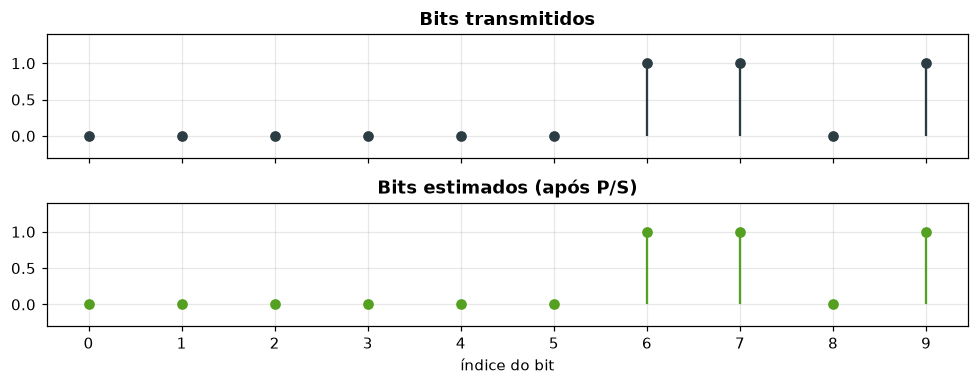

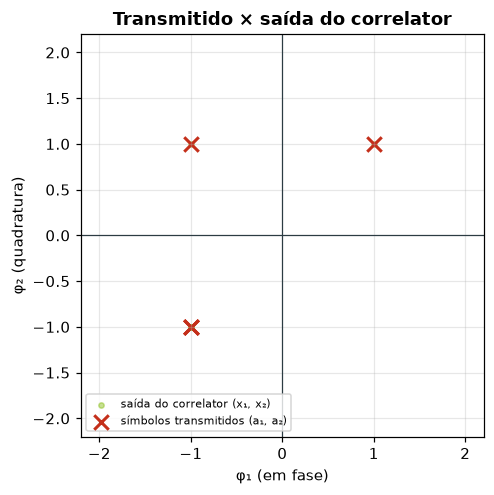

In [13]:
plot_bits(bits, bits_est)
plot_constelacao(a1k, a2k, x1, x2, Eb=Eb, titulo="Transmitido × saída do correlator")

---
## Parte 3 — E se…? (análise de sensibilidade)

A função abaixo reúne toda a cadeia que você implementou, com quatro "botões" para sair do caso ideal. Ela usa as **suas** funções das Partes 1 e 2.

| Parâmetro | Significado |
|---|---|
| `k_port` | ciclos de portadora por símbolo ($f_c = k/T$) — pode ser não inteiro |
| `fase_rx_graus` | erro de fase da portadora local no receptor |
| `EbN0_dB` | ruído branco gaussiano no canal (`None` = sem ruído) |
| `T_int` | duração da integração no correlator (`"T"` ou `"Tb"`) |

In [14]:
def cadeia_completa(bits, k_port=k, fase_rx_graus=0.0, EbN0_dB=None, T_int="T", semente=1):
    rng = np.random.default_rng(semente)
    fc_ = k_port / T
    a1k_, a2k_ = serial_paralelo(nrz_polar(bits, Eb))
    n = len(a1k_) * Ns
    tt = np.arange(n) * dt
    p1 = np.sqrt(2 / T) * np.cos(2 * np.pi * fc_ * tt)
    p2 = np.sqrt(2 / T) * np.sin(2 * np.pi * fc_ * tt)
    s_ = np.repeat(a1k_, Ns) * p1 + np.repeat(a2k_, Ns) * p2
    if EbN0_dB is not None:                               # AWGN com DEP N0/2
        N0 = Eb / 10 ** (EbN0_dB / 10)
        s_ = s_ + rng.normal(0, np.sqrt(N0 / 2 * fs), n)
    ph = np.deg2rad(fase_rx_graus)                        # portadora local defasada
    r1 = np.sqrt(2 / T) * np.cos(2 * np.pi * fc_ * tt + ph)
    r2 = np.sqrt(2 / T) * np.sin(2 * np.pi * fc_ * tt + ph)
    Nint = Ns if T_int == "T" else Nb                     # integra só o 1º Tb do símbolo?
    x1_ = np.sum((s_ * r1).reshape(-1, Ns)[:, :Nint], axis=1) * dt
    x2_ = np.sum((s_ * r2).reshape(-1, Ns)[:, :Nint], axis=1) * dt
    b_est = paralelo_serial(decisao(x1_), decisao(x2_))
    return a1k_, a2k_, x1_, x2_, b_est

def experimento(titulo, n_bits=2000, **kw):
    if _faltando(nrz_polar(bits, Eb), decisao(np.array([1.0])),
                 paralelo_serial(np.array([1]), np.array([0]))): return
    b = np.random.default_rng(7).integers(0, 2, n_bits)
    a1k_, a2k_, x1_, x2_, b_est = cadeia_completa(b, **kw)
    ber = np.mean(b != b_est)
    plot_constelacao(a1k_, a2k_, x1_, x2_, Eb=Eb, titulo=f"{titulo}\nBER = {ber:.4f}")
    print(f"{titulo}: {np.sum(b != b_est)}/{len(b)} bits errados, BER = {ber:.5f}")

Execute os cenários abaixo, observe a constelação e a taxa de erro de bit (BER) e responda às questões. Você pode (e deve) alterar os valores para testar hipóteses.

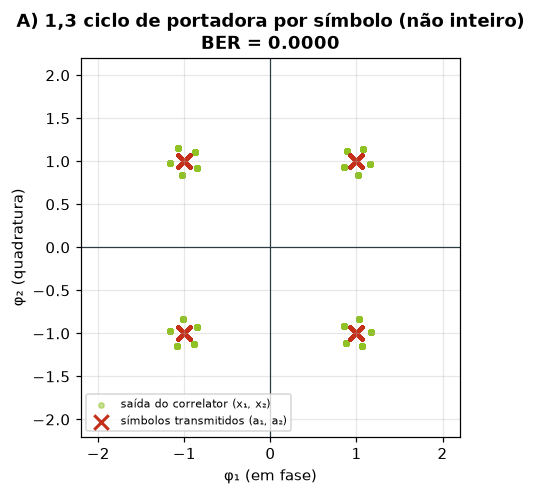

A) 1,3 ciclo de portadora por símbolo (não inteiro): 0/2000 bits errados, BER = 0.00000


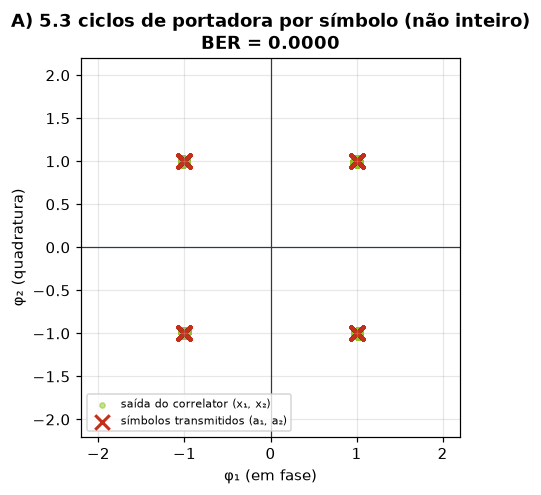

A) 5.3 ciclos de portadora por símbolo (não inteiro): 0/2000 bits errados, BER = 0.00000


In [15]:
experimento("A) 1,3 ciclo de portadora por símbolo (não inteiro)", k_port=1.3)
experimento(f"A) {k + 0.3:.1f} ciclos de portadora por símbolo (não inteiro)", k_port=k + 0.3)

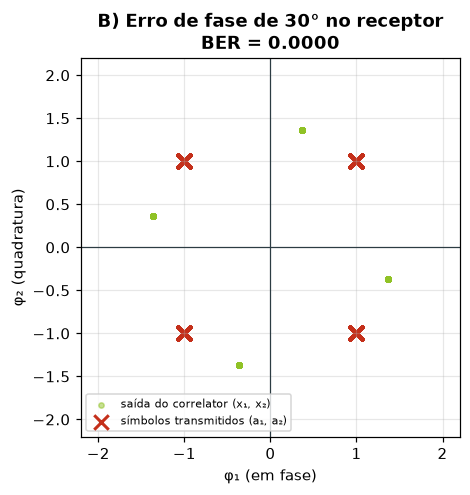

B) Erro de fase de 30° no receptor: 0/2000 bits errados, BER = 0.00000


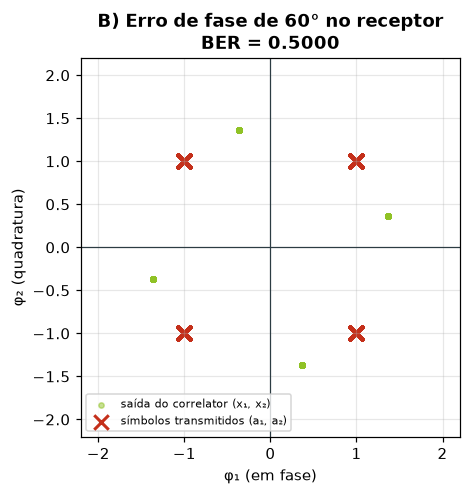

B) Erro de fase de 60° no receptor: 1000/2000 bits errados, BER = 0.50000


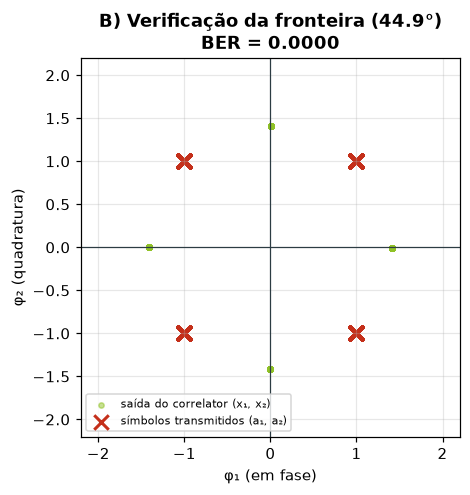

B) Verificação da fronteira (44.9°): 0/2000 bits errados, BER = 0.00000


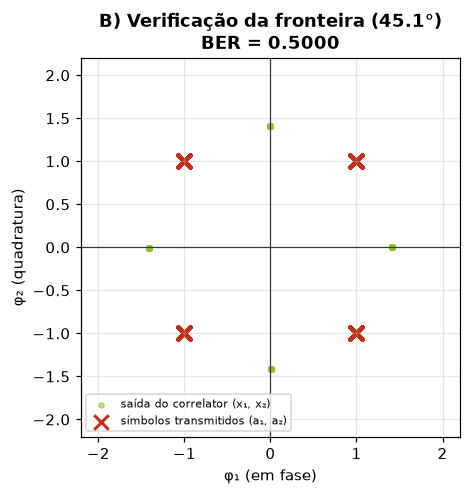

B) Verificação da fronteira (45.1°): 1000/2000 bits errados, BER = 0.50000


In [16]:
experimento("B) Erro de fase de 30° no receptor", fase_rx_graus=30)
experimento("B) Erro de fase de 60° no receptor", fase_rx_graus=60)

for fase in [44.9, 45.1]:
    experimento(f"B) Verificação da fronteira ({fase}°)", fase_rx_graus=fase)

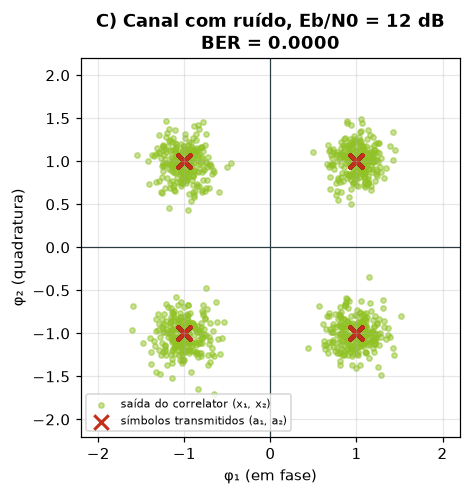

C) Canal com ruído, Eb/N0 = 12 dB: 0/2000 bits errados, BER = 0.00000


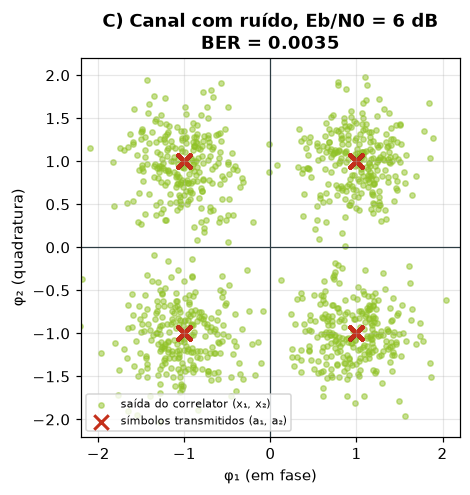

C) Canal com ruído, Eb/N0 = 6 dB: 7/2000 bits errados, BER = 0.00350


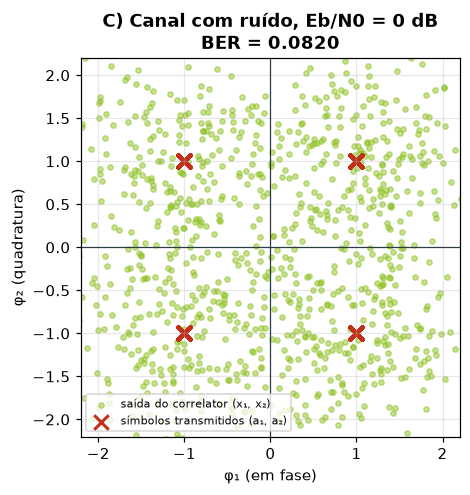

C) Canal com ruído, Eb/N0 = 0 dB: 164/2000 bits errados, BER = 0.08200


In [17]:
for ebn0 in [12, 6, 0]:
    experimento(f"C) Canal com ruído, Eb/N0 = {ebn0} dB", EbN0_dB=ebn0)

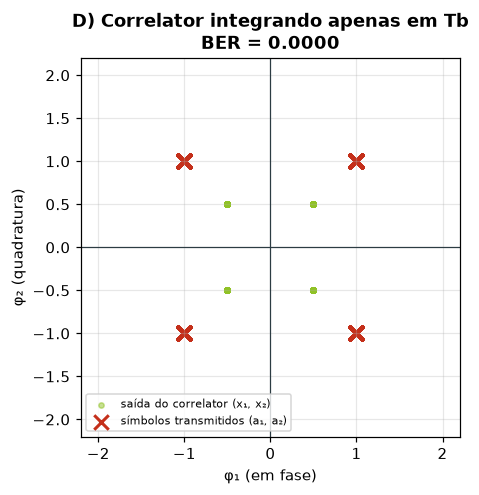

D) Correlator integrando apenas em Tb: 0/2000 bits errados, BER = 0.00000


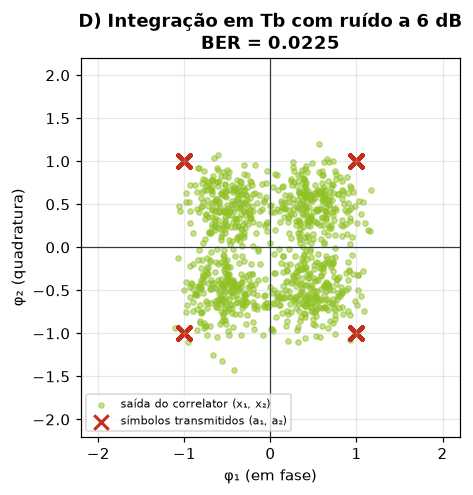

D) Integração em Tb com ruído a 6 dB: 45/2000 bits errados, BER = 0.02250


In [18]:
experimento("D) Correlator integrando apenas em Tb", T_int="Tb")

experimento("D) Integração em Tb com ruído a 6 dB", T_int="Tb", EbN0_dB=6)

**Questão 5 (cenário A)** — O que acontece com a constelação quando $f_c$ não corresponde a um número inteiro de ciclos por símbolo? Qual propriedade da Parte 0.3 deixa de valer? Por que o efeito diminui se $k$ for grande?

**Resposta.** Com 1,3 ciclo por símbolo, cada ponto ideal se desdobra em posições que dependem da fase inicial da janela. Com 5,3 ciclos, o deslocamento é menor. Nos dois casos, os sinais de I e Q foram preservados e houve 0 erro em 2.000 bits. Fora da condição de ortonormalidade, as energias das bases podem diferir de um e surge uma projeção cruzada. Os termos residuais são integrais de senoides em 2fc e sua contribuição relativa cai aproximadamente com 1/(fc T).

**Questão 6 (cenário B)** — Descreva geometricamente o efeito do erro de fase. A partir de qual erro de fase você espera que comecem a surgir erros **mesmo sem ruído**? Teste o valor que você propuser e confirme.

**Resposta.** Um erro positivo gira todos os pontos no sentido anti-horário. Os centros ficam a 45° dos eixos de decisão. A 44,9° houve 0 erro em 2.000 bits. A 45,1° houve 1.000 erros, pois cada símbolo entrou no quadrante vizinho e mudou um dos dois bits. Exatamente a 45° uma projeção é zero e a decisão depende da regra de empate e da precisão numérica. Os testes a 30° e 60° deram, respectivamente, BER 0 e 0,5.

**Questão 7 (cenário C)** — Explique a dispersão dos pontos em torno de cada símbolo. Compare a BER simulada em 6 dB com o valor teórico do QPSK, $P_b = Q\left(\sqrt{2E_b/N_0}\right)$ (use `scipy.special.erfc` se quiser: $Q(x) = \tfrac12\,\text{erfc}(x/\sqrt2)$). Por que, com apenas 10 bits, seria impossível medir essa BER?

**Resposta.** O ruído branco gaussiano projeta em cada eixo uma perturbação de média zero e variância N₀/2. Erra-se um bit quando o ponto atravessa o eixo que delimita sua decisão. A 6 dB, Q(√(2 × 10^(6/10))) ≈ 0,00239. Houve 7 erros em 2.000 bits, BER 0,0035. Em dez bits, o número esperado de erros é apenas 0,024 e a menor BER positiva observável é 0,1. A 0 dB ocorreram 164 erros e a 12 dB nenhum nesta amostra.

**Questão 8 (cenário D)** — Integrar em $T_b$ em vez de $T = 2T_b$ ainda funciona no canal ideal? E com ruído (combine `T_int="Tb"` com `EbN0_dB=6`)? Justifique qual intervalo de integração é o correto para o QPSK e o que se perde com a escolha errada.

**Resposta.** No canal ideal, a primeira metade do símbolo ainda contém 2,5 ciclos e mantém os ramos ortogonais. As projeções caem de ±1 para ±0,5, mas conservam o sinal. A 6 dB, com os mesmos bits e ruído, a integração em 2 ms deu 7/2.000 erros e em 1 ms deu 45/2.000 (BER 0,0225). Ao descartar metade da energia, a média do correlator cai pela metade e sua variância de ruído também. A relação sinal-ruído de decisão cai por um fator dois, cerca de 3 dB.

---
## Log de uso de IA

Registre cada uso relevante de ferramentas de IA, como faria com uma referência bibliográfica. Não há penalidade por usar IA; há penalidade por usá-la sem verificar. Se não usou, escreva "não utilizei".

| # | Ferramenta | O que perguntei (resumo do prompt) | O que aproveitei | Como verifiquei / o que precisei corrigir |
|:-:|---|---|---|---|
| 1 | Codex | Resolver os laboratórios no padrão anterior. | Implementação do NRZ, S/P, bases, correlação e P/S. | A execução verificou as saídas de I/Q contra os coeficientes transmitidos e comparou os dez bits. |
| 2 | Codex | Mesmo pedido, análise das perturbações. | Interpretação dos saltos de fase, nulos e taxa de erro. | Foram comparados 44,9° e 45,1°, a BER teórica a 6 dB e as duas janelas com os mesmos bits e ruído. |
| 3 | Codex | Mesmo pedido, organização da entrega. | Notebook executado e relatório com figuras. | Os números do relatório foram confrontados com as saídas salvas. A previsão digitada está identificada e a foto manuscrita está pendente. |

---
## Entregáveis

Entregue (1) este notebook `.ipynb` **executado** do início ao fim com a sua matrícula, com todas as figuras visíveis; (2) a foto/scan legível da Parte 0 (previsão à mão), feita antes da simulação; e (3) o log de uso de IA preenchido.